# 04 · Pregunta 2b: afinidades entre géneros

**Responsable:** Integrante D · **Plan:** ver `PLAN.md`

¿Qué géneros tienden a gustar juntos, más allá de que se asignen juntos a las mismas películas?

## Preparación

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))


sns.set_theme(style="whitegrid")  # estilo común para todas las figuras del proyecto

from src import contratos, rutas
from src import limpieza, afinidades_generos


## Datos

In [2]:
movies, ratings = limpieza.datos_limpios()
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")
print(movies.shape, ratings.shape)

(9742, 23) (100836, 5)


## 1. Panorama por género

In [3]:
# TODO: tabla por género: n de películas, n de ratings, media, mediana, std

#Agrupamos ratings por movieId y calculamos el número de ratings y la media de los ratings por película
rating_por_pelicula=ratings.groupby('movieId').agg(n_ratings=("rating", "count"), media_rating=("rating", "mean")).reset_index()

#obtenemos la lista de géneros únicos en el dataset de movies
print(movies.columns.tolist())
col_gen=['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

#hacemos el cruce de tablas
tabla_completa=pd.merge(movies[['movieId']+col_gen], rating_por_pelicula, on='movieId', how='left')

#usamos melt para convertir las columnas de géneros en filas
tabla_conv=tabla_completa.melt(
    id_vars=['movieId' ,'n_ratings','media_rating'],
    value_vars=col_gen,
    var_name='genres',
    value_name='has_genre'
)

#Nos quedamos solo la s filas donde has_genre es 1 (es decir, la película pertenece a ese género)
tabla_conv=tabla_conv[tabla_conv['has_genre']==1]

#obtenemos la tabla resumen por género
tabla_resumen=tabla_conv.groupby('genres').agg(n_peliculas=("movieId", "count"),n_ratingsT=("n_ratings", "sum"),mean_rating=("media_rating", "mean"),median_rating=("media_rating", "median"), std_rating=("media_rating", "std") ).reset_index()
print(tabla_resumen)

['movieId', 'title', 'anio', 'n_generos', 'es_imax', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
         genres  n_peliculas  n_ratingsT  mean_rating  median_rating  \
0        Action         1828     30635.0     3.094498       3.200000   
1     Adventure         1263     24161.0     3.215230       3.333333   
2     Animation          611      6988.0     3.497119       3.531751   
3      Children          664      9208.0     3.107690       3.174242   
4        Comedy         3756     39053.0     3.181716       3.250000   
5         Crime         1199     16681.0     3.301844       3.456439   
6   Documentary          440      1219.0     3.781682       4.000000   
7         Drama         4361     41928.0     3.420905       3.500000   
8       Fantasy          779     11834.0     3.218843       3.352419   
9     Film-Noir           87 

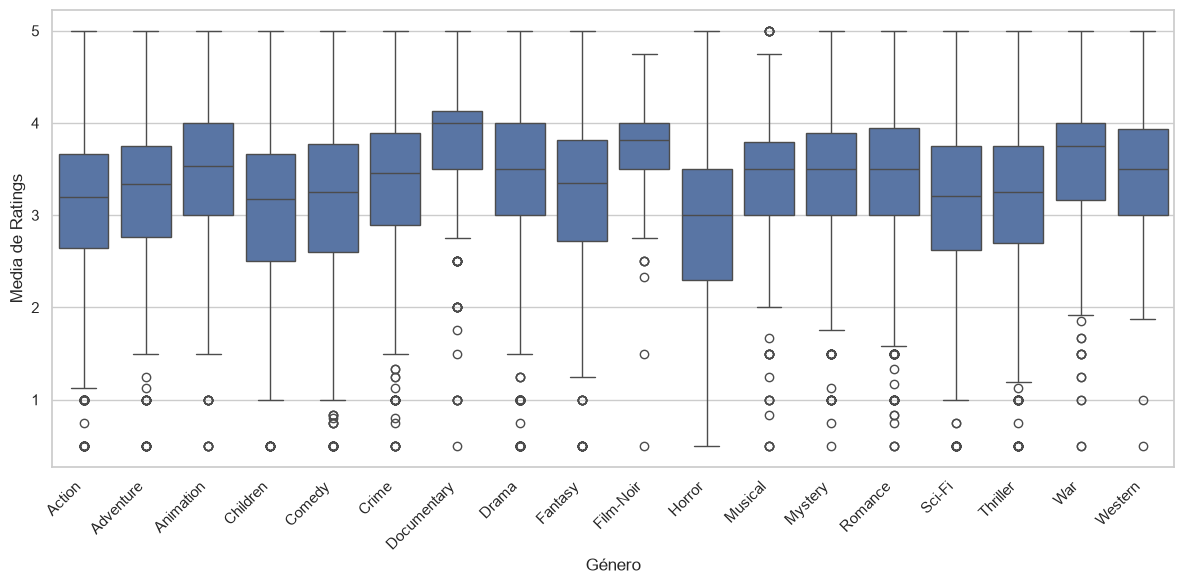

In [4]:
# TODO: boxplot de ratings por género (sns.boxplot necesita formato largo: una fila por rating y género)
# rutas.guardar_figura(fig, "04_boxplot_generos")
plt.figure(figsize=(12, 6))
sns.boxplot(x='genres', y='media_rating', data=tabla_conv)

plt.xlabel('Género', fontsize=12)
plt.ylabel('Media de Ratings', fontsize=12)
plt.xticks(rotation=45,ha='right')
plt.tight_layout()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 2. Coocurrencia de géneros

Correlación entre las 18 columnas 0/1 de `movies`.

             Action  Adventure  Animation  Children  Comedy  Crime  \
Action         1.00       0.29       0.03     -0.05   -0.15   0.15   
Adventure      0.29       1.00       0.21      0.27   -0.06  -0.09   
Animation      0.03       0.21       1.00      0.44    0.03  -0.07   
Children      -0.05       0.27       0.44      1.00    0.09  -0.09   
Comedy        -0.15      -0.06       0.03      0.09    1.00  -0.08   
Crime          0.15      -0.09      -0.07     -0.09   -0.08   1.00   
Documentary   -0.10      -0.08      -0.05     -0.06   -0.13  -0.07   
Drama         -0.15      -0.16      -0.16     -0.16   -0.28   0.06   
Fantasy        0.06       0.26       0.20      0.23   -0.01  -0.09   
Film-Noir     -0.03      -0.03      -0.02     -0.03   -0.07   0.14   
Horror        -0.04      -0.10      -0.06     -0.08   -0.13  -0.06   
Musical       -0.08      -0.01       0.11      0.14    0.05  -0.06   
Mystery       -0.03      -0.05      -0.03     -0.04   -0.13   0.12   
Romance       -0.15 

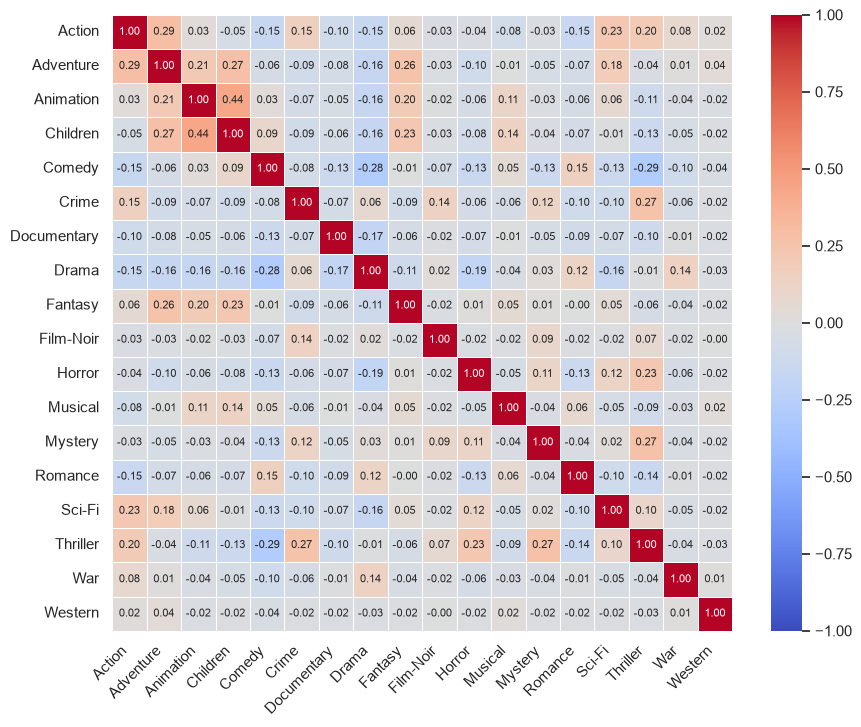

In [5]:
# TODO: matriz de correlación de coocurrencia
matriz_corr=movies[col_gen].corr()
print(matriz_corr.round(2))
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, annot_kws={'size': 8}, fmt='.2f', cmap='coolwarm',vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

## 3. Preferencias por género

In [6]:
perfil = afinidades_generos.perfil_genero(ratings, movies, min_r=5)
contratos.verificar_matriz(perfil, "proporcion", contratos.GENEROS)
perfil.shape

(610, 18)

             Action  Adventure  Animation  Children  Comedy  Crime  \
Action         1.00       0.85       0.63      0.62    0.71   0.72   
Adventure      0.85       1.00       0.79      0.77    0.74   0.63   
Animation      0.63       0.79       1.00      0.91    0.79   0.60   
Children       0.62       0.77       0.91      1.00    0.77   0.58   
Comedy         0.71       0.74       0.79      0.77    1.00   0.75   
Crime          0.72       0.63       0.60      0.58    0.75   1.00   
Documentary    0.58       0.61       0.62      0.48    0.73   0.63   
Drama          0.70       0.70       0.72      0.69    0.77   0.81   
Fantasy        0.69       0.80       0.82      0.82    0.76   0.61   
Film-Noir      0.62       0.68       0.63      0.51    0.76   0.79   
Horror         0.68       0.60       0.54      0.51    0.60   0.64   
Musical        0.60       0.70       0.82      0.81    0.73   0.63   
Mystery        0.73       0.65       0.58      0.54    0.69   0.76   
Romance        0.66 

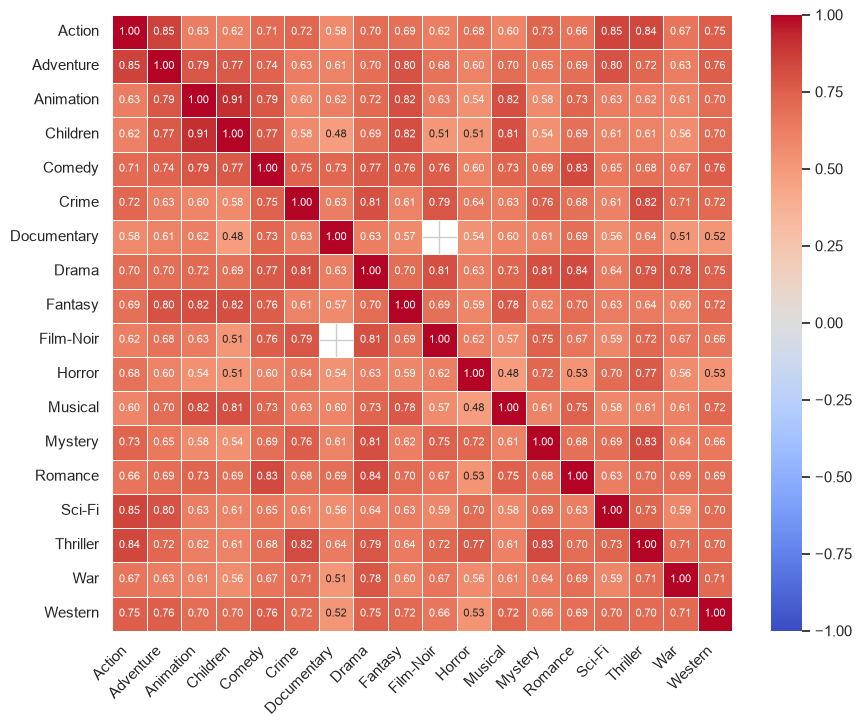

In [7]:
# TODO: matriz de correlación de preferencias (min_periods)
matriz_corr_pref = perfil.corr(min_periods=30)
print(matriz_corr_pref.round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr_pref, annot=True, annot_kws={'size': 8}, fmt='.2f', cmap='coolwarm',vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

## 4. Preferencia vs. coocurrencia

C:\Users\Andres Sanchez\AppData\Local\Temp\ipykernel_48216\2318881499.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


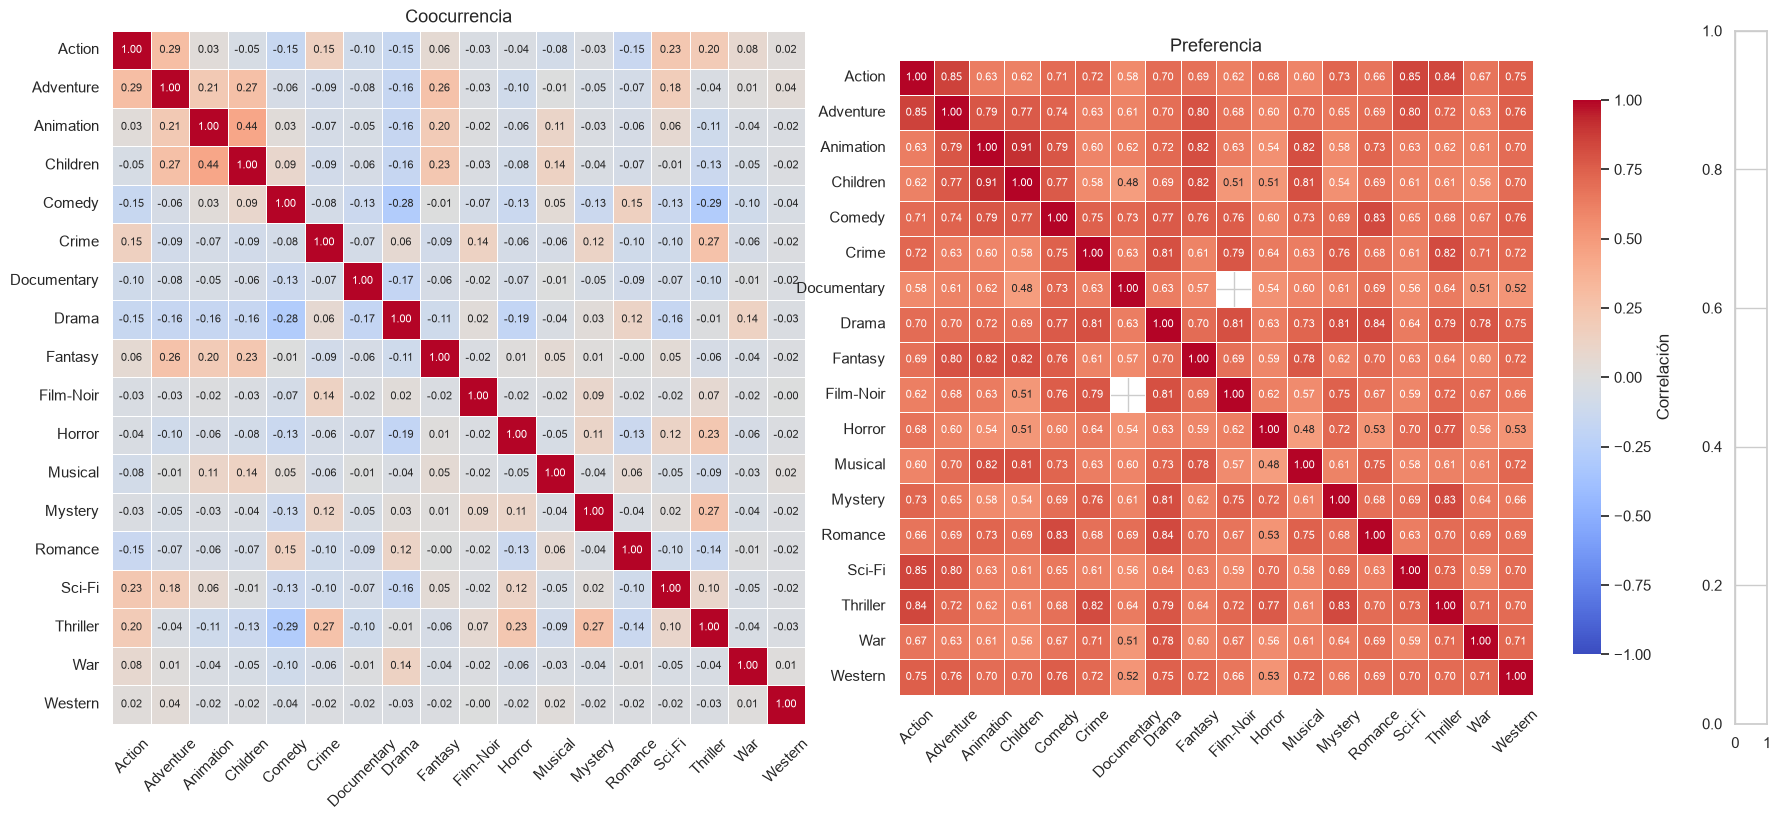

In [8]:
# TODO: los dos heatmaps lado a lado: plt.subplots(1, 2) y sns.heatmap(..., ax=ax) con la misma escala (vmin, vmax)
# rutas.guardar_figura(fig, "04_heatmaps_generos")
vmin, vmax = -1.0, 1.0
fig, (ax1, ax2, cbar_ax) = plt.subplots(1,3,figsize=(22, 9),gridspec_kw={"width_ratios": [1, 1, 0.04], "wspace": 0.08},)
sns.heatmap(
    matriz_corr,
    ax=ax1,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    center=0,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    cbar=False,  
)
ax1.set_title("Coocurrencia", fontsize=13)
ax1.tick_params(axis="x", rotation=45)
ax1.tick_params(axis="y", rotation=0)

# --- Heatmap Derecho (axes) ---
sns.heatmap(
    matriz_corr_pref,
    ax=ax2,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    center=0,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    cbar=cbar_ax,
    cbar_kws={"label": "Correlación", "shrink": 0.8},
)
ax2.set_title("Preferencia", fontsize=13)
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()

rutas.guardar_figura(fig, "04_heatmaps_generos")
plt.show()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

In [9]:
# TODO: scatter de los 153 pares: x = coocurrencia, y = preferencia
# rutas.guardar_figura(fig, "04_scatter_pares")

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 5. Conclusión y limitaciones

…